# 4. Beyond accuracy: diversity, novelty, popularity bias
Accuracy is not the only goal. This notebook measures what the ranker recommends (coverage,
novelty, concentration on popular articles) and what MMR re-ranking trades away for variety.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from hmrec import workspace
pd.set_option("display.width", 140); plt.rcParams["figure.dpi"] = 110

# 10% of customers, seeded. Falls back to a tiny synthetic fixture (with a warning) if the
# real data has not been downloaded yet.
W = workspace.setup(sample_frac=0.10, seed=0)
hm, split = W.hm, W.split
if W.synthetic:
    print("*** SYNTHETIC DATA - numbers below are not H&M results ***")

In [2]:
from hmrec import models as Mo, candidates as C, ranker as R
from hmrec.rerank import mmr_rerank
def sources(ctx):
    return {"repurchase": C.Source(Mo.Repurchase(28).fit(ctx), 40), "popularity": C.Source(Mo.Popularity(7).fit(ctx), 30),
            "co_purchase": C.Source(Mo.CoPurchase(days=56).fit(ctx), 50), "als": C.Source(Mo.ALS(factors=64, days=26 * 7).fit(ctx), 50)}
pool_val = C.generate(sources(W.ctx_train), W.ev_val.users, W.ev_val.rel)
pool_test = C.generate(sources(W.ctx_fit), W.ev_test.users, W.ev_test.rel)
fv = R.FeatureBuilder(hm, W.ctx_train, W.emb).featurize(pool_val.frame)
ft = R.FeatureBuilder(hm, W.ctx_fit, W.emb).featurize(pool_test.frame)
feats = [c for c in fv.columns if c not in ("user", "item", "label")]
rk = R.train_ranker(fv, feats, seed=0)
ranked, scores = R.rank_pool(rk, ft, W.ev_test.users)
base = W.ev_test.metrics_from_ranking(ranked, "ranker")
pd.Series({k: v for k, v in base.summary.items() if k in ("map@12","coverage","novelty","gini","head_share","tail_share","tag_ild","content_ild","arp")}).round(4).to_frame("ranker")

,ranker
map@12,0.0311
coverage,0.0464
gini,0.9941
novelty,9.3253
arp,188.2439
head_share,0.5382
tail_share,0.0000
tag_ild,0.6054
content_ild,0.5564


## MMR trade-off
`lambda=1` is the plain ranker; smaller values favour variety (cosine distance of description embeddings).

In [3]:
rows = {}
for lam in (1.0, 0.9, 0.8, 0.7, 0.5, 0.3):
    r = W.ev_test.metrics_from_ranking(mmr_rerank(ranked, scores, W.emb, 12, lam), f"mmr {lam}")
    rows[lam] = {k: r.summary[k] for k in ("map@12", "recall@12", "coverage", "novelty", "head_share", "tag_ild", "content_ild")}
sweep = pd.DataFrame(rows).T; sweep.index.name = "lambda"; sweep.round(4)

,map@12,recall@12,coverage,novelty,head_share,tag_ild,content_ild
lambda,,,,,,,
1.0,0.0311,0.0659,0.0464,9.3253,0.5382,0.6054,0.5564
0.9,0.0307,0.0652,0.0463,9.3139,0.5398,0.6102,0.5653
0.8,0.0305,0.0648,0.0465,9.2989,0.5433,0.6160,0.5760
0.7,0.0299,0.0639,0.0467,9.2784,0.5477,0.6226,0.5881
0.5,0.0281,0.0596,0.0474,9.2217,0.5619,0.6388,0.6168
0.3,0.0261,0.0523,0.0484,9.1593,0.5819,0.6552,0.6449


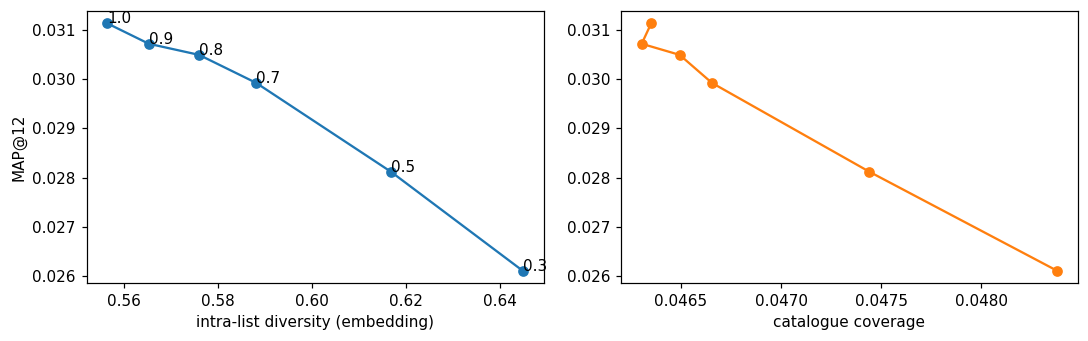

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(sweep["content_ild"], sweep["map@12"], "o-"); ax[0].set_xlabel("intra-list diversity (embedding)"); ax[0].set_ylabel("MAP@12")
for lam, r in sweep.iterrows(): ax[0].annotate(f"{lam}", (r["content_ild"], r["map@12"]))
ax[1].plot(sweep["coverage"], sweep["map@12"], "o-", color="C1"); ax[1].set_xlabel("catalogue coverage"); plt.tight_layout(); plt.show()

**Reading:** find the knee where diversity rises while MAP@12 barely moves. Note the diversity
metric uses the same embeddings MMR optimises, so `tag_ild` (category-based) is the independent check.